# DQN Physics Optimizer -- Training Notebook

This notebook implements a **Deep Q-Network (DQN)** agent that learns to
balance a pole on a cart in the `CartPole-v1` environment from the
Gymnasium library.

---

**Environment:** CartPole-v1 (discrete action space, continuous state space)  
**Algorithm:** DQN with experience replay and target network  
**Framework:** PyTorch  
**Solved criterion:** Average reward >= 475 over 100 consecutive episodes  

## 1. Imports and Configuration

In [ ]:
import random
from collections import deque, namedtuple

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# ---- Hyperparameters ----
GAMMA = 0.99               # Discount factor for future rewards
LEARNING_RATE = 1e-3       # Adam optimizer learning rate
BATCH_SIZE = 128            # Mini-batch size sampled from replay buffer
BUFFER_CAPACITY = 10000   # Maximum transitions stored in replay memory
EPSILON_START = 1.0        # Initial exploration probability
EPSILON_END = 0.01         # Minimum exploration probability
EPSILON_DECAY = 0.995      # Multiplicative decay applied each episode
TARGET_UPDATE_FREQ = 10    # Episodes between target network syncs
NUM_EPISODES = 1000         # Maximum training episodes
MAX_STEPS = 500            # Maximum steps per episode (CartPole-v1 limit)
SOLVED_REWARD = 475.0      # Average reward threshold to consider solved

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


## 2. Environment Overview

CartPole-v1 has:
- **State space:** 4 continuous values  
  - Cart position (-4.8 to 4.8)  
  - Cart velocity (-inf to inf)  
  - Pole angle (-0.418 rad to 0.418 rad)  
  - Pole angular velocity (-inf to inf)  
- **Action space:** 2 discrete actions  
  - 0 = push cart left  
  - 1 = push cart right  
- **Reward:** +1 for every timestep the pole remains upright  
- **Termination:** pole angle > 12 degrees, cart leaves bounds, or 500 steps reached  

In [2]:
env = gym.make("CartPole-v1")
STATE_DIM = env.observation_space.shape[0]   # 4
ACTION_DIM = env.action_space.n              # 2
print(f"State dimension:  {STATE_DIM}")
print(f"Action dimension: {ACTION_DIM}")
env.close()

State dimension:  4
Action dimension: 2


## 3. DQN Architecture

The Q-network is a simple feedforward neural network that maps a
4-dimensional state vector to Q-values for each of the 2 possible
actions. The agent selects the action with the highest Q-value
(greedy policy) or explores randomly (epsilon-greedy).

In [4]:
class DQNetwork(nn.Module):
    """
    Deep Q-Network for CartPole-v1.

    This network approximates the optimal action-value function Q*(s, a),
    which represents the expected cumulative discounted reward of taking
    action `a` in state `s` and then following the optimal policy.

    Architecture:
        Input (4) -> FC(128) -> ReLU -> FC(128) -> ReLU -> Output (2)

    The two hidden layers with 128 units each provide sufficient capacity
    to learn the CartPole value function without overfitting.
    """

    def __init__(self, state_dim: int, action_dim: int):
        super(DQNetwork, self).__init__()
        self.network = nn.Sequential(
            # Layer 1: Maps the raw state vector into a learned 128-dimensional embedding.This layer captures non-linear combinations of the 4 state variables.
            nn.Linear(state_dim, 128),
            nn.ReLU(inplace=True),

            # Layer 2: Deeper hidden representation allows the
            # network to model more complex decision boundaries
            # between "push left" and "push right".
            nn.Linear(128, 128),
            nn.ReLU(inplace=True),

            # Output layer: Produces one Q-value per action.
            # No activation here -- Q-values are unbounded reals.
            nn.Linear(128, action_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass.

        Args:
            x: State tensor of shape (batch, state_dim).

        Returns:
            Q-value tensor of shape (batch, action_dim).
        """
        return self.network(x)


# ---- Instantiate networks ----
# policy_net: the network we actively train
# target_net: a periodic snapshot of policy_net used to compute
#             stable TD targets (reduces oscillation / divergence)
policy_net = DQNetwork(STATE_DIM, ACTION_DIM).to(DEVICE)
target_net = DQNetwork(STATE_DIM, ACTION_DIM).to(DEVICE)
target_net.load_state_dict(policy_net.state_dict())  # initialise identically
target_net.eval()  # target net is never trained directly

print(policy_net)
total_params = sum(p.numel() for p in policy_net.parameters())
print(f"\nTotal trainable parameters: {total_params:,}")

DQNetwork(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

Total trainable parameters: 17,410


## 4. Experience Replay Buffer

Experience replay stores past transitions `(s, a, r, s', done)` and
samples random mini-batches for training.  This breaks temporal
correlations between consecutive samples, which dramatically improves
training stability compared to online (one-step) learning.

In [5]:
# Named tuple for clean, readable transition storage
Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])


class ReplayBuffer:
    """
    Fixed-capacity circular buffer that stores experience tuples and
    supports uniform random sampling.
    """

    def __init__(self, capacity: int):
        # deque with maxlen automatically discards the oldest item
        # when the buffer reaches capacity.
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        """Store a single transition."""
        self.buffer.append(Transition(state, action, reward, next_state, done))

    def sample(self, batch_size: int) -> list[Transition]:
        """Sample a random mini-batch of transitions."""
        return random.sample(self.buffer, batch_size)

    def __len__(self) -> int:
        return len(self.buffer)


replay_buffer = ReplayBuffer(BUFFER_CAPACITY)
print(f"Replay buffer initialised with capacity {BUFFER_CAPACITY:,}")

Replay buffer initialised with capacity 50,000


## 5. Optimizer and Loss

- **Optimizer:** Adam (adaptive learning rate per parameter)  
- **Loss:** Smooth L1 (Huber loss) -- behaves like MSE for small errors
  and like MAE for large errors, making it more robust to outlier
  TD-error spikes.

In [6]:
optimizer = optim.Adam(policy_net.parameters(), lr=LEARNING_RATE)
loss_fn = nn.SmoothL1Loss()  # Huber loss

## 6. Action Selection (Epsilon-Greedy)

With probability `epsilon`, the agent takes a random action (exploration).
Otherwise, it takes the action with the highest predicted Q-value
(exploitation).  `epsilon` decays over time so the agent gradually
shifts from exploring to exploiting its learned policy.

In [8]:
def select_action(state: np.ndarray, epsilon: float) -> int:
    """
    Epsilon-greedy action selection.

    Args:
        state:   Current environment state (numpy array).
        epsilon: Probability of choosing a random action.

    Returns:
        action: Integer action (0 = left, 1 = right).
    """
    if random.random() < epsilon:
        # Exploration: random action
        return random.randint(0, ACTION_DIM - 1)
    else:
        # Exploitation: greedy action from Q-network
        state_tensor = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        with torch.no_grad():
            q_values = policy_net(state_tensor)
        return torch.argmax(q_values, dim=1).item()

## 7. Training Step (Bellman Update)

Each training step samples a mini-batch from replay memory and
minimises the temporal-difference (TD) error:

    loss = Huber( Q(s,a) - [r + gamma * max_a' Q_target(s', a')] )

The target network provides the `Q_target` values, which are not
backpropagated through.  This "semi-gradient" approach prevents
moving-target instability.

In [9]:
def train_step():
    """
    Perform one gradient descent step on a mini-batch from the replay buffer.
    Does nothing if the buffer has fewer samples than BATCH_SIZE.
    """
    if len(replay_buffer) < BATCH_SIZE:
        return

    # ---- Sample a mini-batch ----
    transitions = replay_buffer.sample(BATCH_SIZE)
    batch = Transition(*zip(*transitions))  # transpose list-of-tuples

    # Convert to tensors
    state_batch = torch.tensor(np.array(batch.state), dtype=torch.float32, device=DEVICE)
    action_batch = torch.tensor(batch.action, dtype=torch.long, device=DEVICE).unsqueeze(1)
    reward_batch = torch.tensor(batch.reward, dtype=torch.float32, device=DEVICE).unsqueeze(1)
    next_state_batch = torch.tensor(np.array(batch.next_state), dtype=torch.float32, device=DEVICE)
    done_batch = torch.tensor(batch.done, dtype=torch.float32, device=DEVICE).unsqueeze(1)

    # ---- Compute current Q-values ----
    # Q(s, a): gather selects the Q-value for the action actually taken
    current_q = policy_net(state_batch).gather(1, action_batch)

    # ---- Compute target Q-values ----
    # For terminal states (done=1), the target is just the immediate reward.
    # For non-terminal states: r + gamma * max_a' Q_target(s', a')
    with torch.no_grad():
        max_next_q = target_net(next_state_batch).max(dim=1, keepdim=True)[0]
        target_q = reward_batch + GAMMA * max_next_q * (1.0 - done_batch)

    # ---- Compute loss and update weights ----
    loss = loss_fn(current_q, target_q)
    optimizer.zero_grad()
    loss.backward()
    # Gradient clipping prevents exploding gradients
    torch.nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=1.0)
    optimizer.step()

## 8. Training Loop

In [10]:
env = gym.make("CartPole-v1")

epsilon = EPSILON_START
episode_rewards = []   # reward per episode (for plotting)
solved = False

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    total_reward = 0.0

    for step in range(MAX_STEPS):
        # Select action using epsilon-greedy strategy
        action = select_action(state, epsilon)

        # Execute action in environment
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Store transition in replay buffer
        replay_buffer.push(state, action, reward, next_state, float(done))

        # Perform one gradient update
        train_step()

        state = next_state
        total_reward += reward

        if done:
            break

    # Record episode reward
    episode_rewards.append(total_reward)

    # Decay epsilon (reduce exploration over time)
    epsilon = max(EPSILON_END, epsilon * EPSILON_DECAY)

    # Periodically sync target network with policy network
    if episode % TARGET_UPDATE_FREQ == 0:
        target_net.load_state_dict(policy_net.state_dict())

    # Check solved condition (average over last 100 episodes)
    if len(episode_rewards) >= 100:
        avg_reward = np.mean(episode_rewards[-100:])
        if episode % 50 == 0:
            print(
                f"Episode {episode:4d} | "
                f"Reward: {total_reward:6.1f} | "
                f"Avg(100): {avg_reward:6.1f} | "
                f"Epsilon: {epsilon:.4f}"
            )
        if avg_reward >= SOLVED_REWARD and not solved:
            print(f"\nEnvironment SOLVED at episode {episode} with average reward {avg_reward:.1f}")
            solved = True
            break
    elif episode % 50 == 0:
        print(
            f"Episode {episode:4d} | "
            f"Reward: {total_reward:6.1f} | "
            f"Epsilon: {epsilon:.4f}"
        )

env.close()

if not solved:
    print(
        f"\nTraining finished after {NUM_EPISODES} episodes. "
        f"Final avg(100): {np.mean(episode_rewards[-100:]):.1f}"
    )
    print("The agent may need more episodes or hyperparameter tuning.")

Episode   50 | Reward:   18.0 | Epsilon: 0.9047
Episode  100 | Reward:   70.0 | Avg(100):   26.5 | Epsilon: 0.8186
Episode  150 | Reward:   12.0 | Avg(100):   28.9 | Epsilon: 0.7406
Episode  200 | Reward:   27.0 | Avg(100):   26.4 | Epsilon: 0.6701
Episode  250 | Reward:   22.0 | Avg(100):   23.3 | Epsilon: 0.6062
Episode  300 | Reward:   57.0 | Avg(100):   28.8 | Epsilon: 0.5485
Episode  350 | Reward:   31.0 | Avg(100):   36.4 | Epsilon: 0.4962
Episode  400 | Reward:   40.0 | Avg(100):   43.0 | Epsilon: 0.4490
Episode  450 | Reward:   18.0 | Avg(100):   43.5 | Epsilon: 0.4062
Episode  500 | Reward:  197.0 | Avg(100):   39.3 | Epsilon: 0.3675
Episode  550 | Reward:   27.0 | Avg(100):   40.9 | Epsilon: 0.3325
Episode  600 | Reward:   49.0 | Avg(100):   57.5 | Epsilon: 0.3008
Episode  650 | Reward:   40.0 | Avg(100):   63.4 | Epsilon: 0.2722
Episode  700 | Reward:   12.0 | Avg(100):   70.1 | Epsilon: 0.2463
Episode  750 | Reward:  398.0 | Avg(100):  121.0 | Epsilon: 0.2228
Episode  800 |

## 9. Training Curve

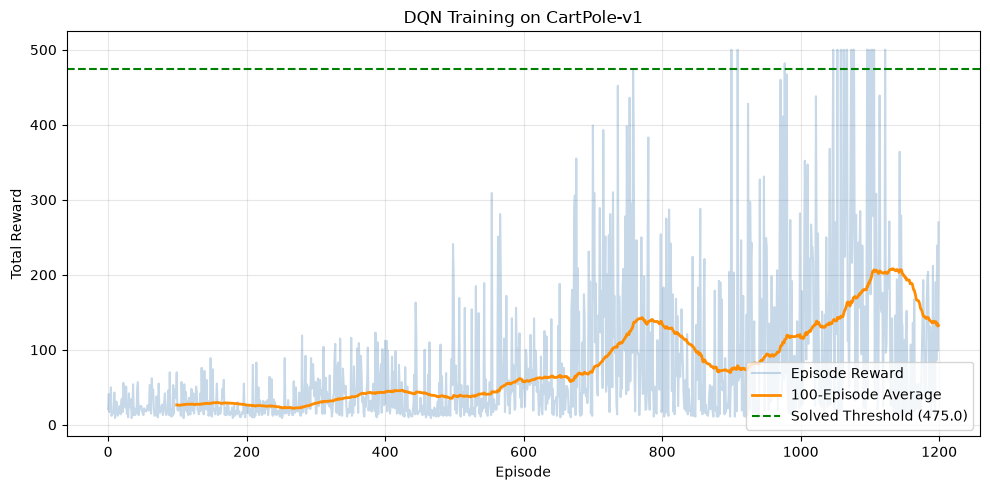

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(episode_rewards, alpha=0.3, color="steelblue", label="Episode Reward")

# Compute and overlay 100-episode rolling average
if len(episode_rewards) >= 100:
    rolling_avg = np.convolve(episode_rewards, np.ones(100) / 100, mode="valid")
    ax.plot(
        range(99, len(episode_rewards)),
        rolling_avg,
        color="darkorange",
        linewidth=2,
        label="100-Episode Average",
    )

ax.axhline(y=SOLVED_REWARD, color="green", linestyle="--", label=f"Solved Threshold ({SOLVED_REWARD})")
ax.set_xlabel("Episode")
ax.set_ylabel("Total Reward")
ax.set_title("DQN Training on CartPole-v1")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Save Trained Agent

In [ ]:
MODEL_PATH = "dqn_agent.pth"
torch.save(policy_net.state_dict(), MODEL_PATH)
print(f"DQN agent weights saved to: {MODEL_PATH}")

## 11. Validation: Run a Test Episode

In [ ]:
# Load the saved model and run 10 greedy episodes to validate performance
val_net = DQNetwork(STATE_DIM, ACTION_DIM).to(DEVICE)
val_net.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
val_net.eval()

val_env = gym.make("CartPole-v1")
val_rewards = []

for ep in range(10):
    state, _ = val_env.reset()
    ep_reward = 0.0
    for _ in range(MAX_STEPS):
        state_t = torch.tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
        with torch.no_grad():
            action = torch.argmax(val_net(state_t), dim=1).item()
        state, reward, terminated, truncated, _ = val_env.step(action)
        ep_reward += reward
        if terminated or truncated:
            break
    val_rewards.append(ep_reward)
    print(f"  Validation episode {ep + 1:2d}: reward = {ep_reward:.0f}")

val_env.close()
print(f"\nValidation average: {np.mean(val_rewards):.1f} (over 10 episodes)")